<a href="https://colab.research.google.com/github/animeshpaudel94-commits/CN5006/blob/main/Na%C3%AFve_Bayes_and_Sentiment_in_Python.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import nltk
from sklearn.naive_bayes import CategoricalNB, MultinomialNB
from sklearn.preprocessing import OrdinalEncoder
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

nltk.download("movie_reviews", quiet=True)
nltk.download("vader_lexicon", quiet=True)


True

**Part A: Naïve Bayes by hand, checked in code**

In [2]:
tennis = pd.DataFrame({
 "Outlook":  ["Sunny","Sunny","Overcast","Rain","Rain","Rain","Overcast","Sunny","Sunny","Rain","Sunny","Overcast","Overcast","Rain"],
 "Temp":     ["Hot","Hot","Hot","Mild","Cool","Cool","Cool","Mild","Cool","Mild","Mild","Mild","Hot","Mild"],
 "Humidity": ["High","High","High","High","Normal","Normal","Normal","High","Normal","Normal","Normal","High","Normal","High"],
 "Wind":     ["Weak","Strong","Weak","Weak","Weak","Strong","Strong","Weak","Weak","Weak","Strong","Strong","Weak","Strong"],
 "Play":     ["No","No","Yes","Yes","Yes","No","Yes","No","Yes","Yes","Yes","Yes","Yes","No"],
})
tennis

,Outlook,Temp,Humidity,Wind,Play
0,Sunny,Hot,High,Weak,No
1,Sunny,Hot,High,Strong,No
2,Overcast,Hot,High,Weak,Yes
3,Rain,Mild,High,Weak,Yes
4,Rain,Cool,Normal,Weak,Yes
5,Rain,Cool,Normal,Strong,No
6,Overcast,Cool,Normal,Strong,Yes
7,Sunny,Mild,High,Weak,No
8,Sunny,Cool,Normal,Weak,Yes
9,Rain,Mild,Normal,Weak,Yes


**Task A1: a Naïve Bayes scorer**

In [3]:
def nb_scores(df, target, example, alpha=0):
    scores = {}
    for c, subset in df.groupby(target):
        score = len(subset) / len(df)                       # prior P(C)
        for feature, value in example.items():
            count = (subset[feature] == value).sum()
            k = df[feature].nunique()                       # number of possible values
            score *= (count + alpha) / (len(subset) + alpha * k)
        scores[c] = score
    total = sum(scores.values())
    return {c: (round(s, 4), round(s / total, 3)) for c, s in scores.items()}   # (score, normalised probability)

x_new = {"Outlook": "Sunny", "Temp": "Cool", "Humidity": "High", "Wind": "Strong"}
print(nb_scores(tennis, "Play", x_new))       # expect Yes 0.0053, No 0.0206

{'No': (np.float64(0.0206), np.float64(0.795)), 'Yes': (np.float64(0.0053), np.float64(0.205))}


**Task A2: the zero-frequency problem**

In [4]:
x_over = {"Outlook": "Overcast", "Temp": "Hot", "Humidity": "High", "Wind": "Strong"}
print("No smoothing:  ", nb_scores(tennis, "Play", x_over, alpha=0))
print("Laplace (a=1): ", nb_scores(tennis, "Play", x_over, alpha=1))

No smoothing:   {'No': (np.float64(0.0), np.float64(0.0)), 'Yes': (np.float64(0.0071), np.float64(1.0))}
Laplace (a=1):  {'No': (np.float64(0.0068), np.float64(0.436)), 'Yes': (np.float64(0.0089), np.float64(0.564))}


**Task A3: the same model in scikit-learn**

In [5]:
enc = OrdinalEncoder()
X_t = enc.fit_transform(tennis.drop(columns="Play"))
model = CategoricalNB(alpha=1).fit(X_t, tennis["Play"])

query = enc.transform(pd.DataFrame([x_new]))
print(dict(zip(model.classes_, model.predict_proba(query)[0].round(3))))
print("Hand version with alpha=1:", nb_scores(tennis, "Play", x_new, alpha=1))

{np.str_('No'): np.float64(0.72), np.str_('Yes'): np.float64(0.28)}
Hand version with alpha=1: {'No': (np.float64(0.0182), np.float64(0.72)), 'Yes': (np.float64(0.0071), np.float64(0.28))}


**Part B: sentiment analysis of film reviews**

In [6]:
from nltk.corpus import movie_reviews
reviews = pd.DataFrame(
    [(movie_reviews.raw(f), cat) for cat in movie_reviews.categories() for f in movie_reviews.fileids(cat)],
    columns=["text", "label"])
print(reviews["label"].value_counts())
print("Average length:", int(reviews["text"].str.split().str.len().mean()), "words")
print(reviews["text"][0][:500])

label
neg    1000
pos    1000
Name: count, dtype: int64
Average length: 746 words
plot : two teen couples go to a church party , drink and then drive . 
they get into an accident . 
one of the guys dies , but his girlfriend continues to see him in her life , and has nightmares . 
what's the deal ? 
watch the movie and " sorta " find out . . . 
critique : a mind-fuck movie for the teen generation that touches on a very cool idea , but presents it in a very bad package . 
which is what makes this review an even harder one to write , since i generally applaud films which attempt


**Task B1: bag of words + Multinomial Naïve Bayes**

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    reviews["text"], reviews["label"], test_size=0.2, random_state=42, stratify=reviews["label"])
print(len(X_train), "training reviews,", len(X_test), "test reviews")

1600 training reviews, 400 test reviews


**Task B2: does TF-IDF or adding two-word phrases help?**

Accuracy: 0.8
              precision    recall  f1-score   support

         neg       0.80      0.80      0.80       200
         pos       0.80      0.80      0.80       200

    accuracy                           0.80       400
   macro avg       0.80      0.80      0.80       400
weighted avg       0.80      0.80      0.80       400



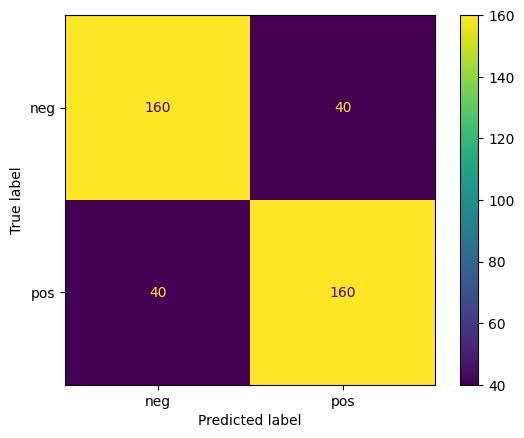

In [8]:
bow_nb = make_pipeline(CountVectorizer(stop_words="english"), MultinomialNB())
bow_nb.fit(X_train, y_train)
pred = bow_nb.predict(X_test)
print("Accuracy:", round(accuracy_score(y_test, pred), 3))
print(classification_report(y_test, pred))
ConfusionMatrixDisplay.from_predictions(y_test, pred); plt.show()

**Task B3: what has the model learned?**

In [9]:
variants = {
    "Counts, stop words removed":         CountVectorizer(stop_words="english"),
    "TF-IDF, stop words removed":         TfidfVectorizer(stop_words="english"),
    "Counts + bigrams, stop words removed": CountVectorizer(stop_words="english", ngram_range=(1, 2)),
    "Counts + bigrams, stop words kept":  CountVectorizer(ngram_range=(1, 2)),
}
results = {}
for name, vec in variants.items():
    m = make_pipeline(vec, MultinomialNB()).fit(X_train, y_train)
    results[name] = round(m.score(X_test, y_test), 3)
pd.Series(results, name="test accuracy")

,test accuracy
"Counts, stop words removed",0.800
"TF-IDF, stop words removed",0.797
"Counts + bigrams, stop words removed",0.792
"Counts + bigrams, stop words kept",0.825


**Task B4: compare with a lexicon method (VADER)**

In [10]:
vec, nb = bow_nb.named_steps["countvectorizer"], bow_nb.named_steps["multinomialnb"]
words = np.array(vec.get_feature_names_out())
neg_i, pos_i = list(nb.classes_).index("neg"), list(nb.classes_).index("pos")
diff = nb.feature_log_prob_[pos_i] - nb.feature_log_prob_[neg_i]
# only words that appear in at least 30 training reviews, so rare names don't dominate
doc_freq = np.asarray((vec.transform(X_train) > 0).sum(axis=0)).ravel()
mask = doc_freq >= 30
order = np.argsort(diff[mask])
print("Most negative words:", list(words[mask][order[:15]]))
print("Most positive words:", list(words[mask][order[-15:]][::-1]))

Most negative words: ['ludicrous', 'idiotic', 'stupidity', 'poorly', 'inept', 'ridiculous', 'lame', 'wasted', 'worst', 'eve', 'uninteresting', 'snake', 'unfunny', 'waste', 'awful']
Most positive words: ['outstanding', 'finest', 'religion', 'wonderfully', 'nomination', 'anger', 'beautifully', 'refreshing', 'harris', 'breathtaking', 'excellent', 'toy', 'delightful', 'terrific', 'portrayal']


**Task B5: break the models**

In [11]:
from nltk.sentiment import SentimentIntensityAnalyzer
vader = SentimentIntensityAnalyzer()
vader_pred = ["pos" if vader.polarity_scores(t)["compound"] >= 0 else "neg" for t in X_test]
print("VADER accuracy:", round(accuracy_score(y_test, vader_pred), 3))
print("Naïve Bayes accuracy:", round(accuracy_score(y_test, pred), 3))
print(classification_report(y_test, vader_pred))

VADER accuracy: 0.647
Naïve Bayes accuracy: 0.8
              precision    recall  f1-score   support

         neg       0.72      0.48      0.58       200
         pos       0.61      0.81      0.70       200

    accuracy                           0.65       400
   macro avg       0.66      0.65      0.64       400
weighted avg       0.66      0.65      0.64       400



In [12]:
my_reviews = [
    "An absolute masterpiece, I loved every minute.",
    "This was not good at all.",
    "Oh great, another two hours of my life I will never get back.",
    "The acting was brilliant but the plot made no sense and it dragged.",
    "I expected to hate it, but it won me over.",
]
pd.DataFrame({
    "review": my_reviews,
    "naive_bayes": bow_nb.predict(my_reviews),
    "nb_prob_pos": bow_nb.predict_proba(my_reviews)[:, list(bow_nb.classes_).index("pos")].round(2),
    "vader_compound": [vader.polarity_scores(r)["compound"] for r in my_reviews],
})

,review,naive_bayes,nb_prob_pos,vader_compound
0,"An absolute masterpiece, I loved every minute.",pos,0.63,0.8402
1,This was not good at all.,neg,0.49,-0.3412
2,"Oh great, another two hours of my life I will ...",pos,0.65,0.6249
3,The acting was brilliant but the plot made no ...,neg,0.42,-0.1779
4,"I expected to hate it, but it won me over.",neg,0.49,0.5719
